In [1]:
import numpy as np

# def softmax(z):
#     exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))  # 数值稳定
#     return exp_z / np.sum(exp_z, axis=1, keepdims=True)
#
# 加载MNIST数据集
def load_mnist():
    with open('mnist.npz', 'rb') as f:
        data = np.load(f)
        train_x, train_y = data['x_train'], data['y_train']
        test_x, test_y = data['x_test'], data['y_test']
    return train_x, train_y, test_x, test_y

# 对卷积层的参数，其本身形如conv1['weights'].value
# 同时具有梯度grad，可通过如
# conv1['weights'].grad = your_calculation
# 对梯度进行保存
class nn_Parameter:
    def __init__(self, value):
        self.value = value
        self.grad = np.zeros_like(value)

# CNN网络结构类
class SimpleCNN:
    def __init__(self):

        self.conv1 = {
            'weights': nn_Parameter(np.random.randn(5, 5, 1, 6)),
            'bias': nn_Parameter(np.zeros(6)),
            'output': np.zeros((24, 24, 6))
        }

        self.pool1 = {
            'weights': np.ones((2, 2)) / 4,
            'output': np.zeros((12, 12, 6))
        }

        self.conv2 = {
            'weights': nn_Parameter(np.random.randn(5, 5, 6, 12)),
            'bias': nn_Parameter(np.zeros(12)),
            'output': np.zeros((8, 8, 12))
        }

        self.pool2 = {
            'weights': np.ones((2, 2)) / 4,
            'output': np.zeros((4, 4, 12))
        }

        self.fc = {
            'weights': nn_Parameter(np.random.randn(12 * 4 * 4, 10)),
            'bias': nn_Parameter(np.zeros(10)),
            'output': np.zeros((10))
        }

    @staticmethod
    def _im2col(input_pad, k_h, k_w, stride):
        # 卷积窗口展开，输入为 H x W x C x N，输出为 (H_out*W_out*N, kH*kW*C)
        # 利用GEMM加速卷积计算

        H, W, C, N = input_pad.shape
        H_out = (H - k_h) // stride + 1
        W_out = (W - k_w) // stride + 1

        shape = (H_out, W_out, k_h, k_w, C, N)
        strides = (stride * input_pad.strides[0], stride * input_pad.strides[1],
                   input_pad.strides[0], input_pad.strides[1],
                   input_pad.strides[2], input_pad.strides[3])

        patches = np.lib.stride_tricks.as_strided(input_pad, shape=shape, strides=strides)
        # (H_out, W_out, kH, kW, C, N) → (H_out, W_out, N, kH, kW, C) → 2D
        patches = patches.transpose(0, 1, 5, 2, 3, 4)
        return np.ascontiguousarray(patches.reshape(H_out * W_out * N, k_h * k_w * C))

    # for循环展开，硬算
    @staticmethod
    def conv2d_base(input, filters, bias, stride=1, padding=0):
        # input   : H x W x C_in x N; N是批次大小
        # filters : F_h x F_w x C_in x c_out; c_out 是每一个卷积核产生的输出通道数
        # bias    : c_out

        if padding > 0:
            input = np.pad(input, ((padding, padding), (padding, padding), (0, 0)), mode='constant')

        ch_in = filters.shape[2]
        ch_out = filters.shape[3]
        ch_width = (input.shape[0] - filters.shape[0]) // stride + 1
        ch_height = (input.shape[1] - filters.shape[1]) // stride + 1
        N = input.shape[3]

        res = np.zeros((ch_width, ch_height, ch_out, N))

        in_h, in_w = input.shape[0], input.shape[1]
        k_h, k_w = filters.shape[0], filters.shape[1]
        # 按输入通道遍历
        for n in range(N):
            for c in range(ch_in):
                # 按输出通道遍历，计算输入对应输出通道的贡献
                for k in range(ch_out):
                    _region = input[:, :, c, n]
                    _kernel = filters[:, :, c, k]
                    for i in range(0, in_h - k_h + 1, stride):
                        for j in range(0, in_w - k_w + 1, stride):
                            res[i // stride, j // stride, k, n] += np.sum(
                                _region[i:i + k_h, j:j + k_w] * _kernel
                            )
        # 添加偏置
        for k in range(ch_out):
            res[:, :, k, :] += bias[k]
        return res

    # for循环展开，硬算
    @staticmethod
    def avg_pool2d_base(input, kernel_size=2):
        # input : H x W x C x N; N是批次大小
        # 默认丢弃边界不完整部分
        # for循环展开，硬算
        ch_in = input.shape[2]
        ch_width = (input.shape[0] - kernel_size) // kernel_size + 1
        ch_height = (input.shape[1] - kernel_size) // kernel_size + 1
        N = input.shape[3]

        res = np.zeros((ch_width, ch_height, ch_in, N))

        in_h, in_w = input.shape[0], input.shape[1]
        for n in range(N):
            for c in range(ch_in):
                _region = input[:, :, c, n]
                for i in range(0, in_h - kernel_size + 1, kernel_size):
                    for j in range(0, in_w - kernel_size + 1, kernel_size):
                        res[i // kernel_size, j // kernel_size, c, n] = np.mean(
                            _region[i:i + kernel_size, j:j + kernel_size]
                        )
        return res

    # for循环展开，硬算
    @staticmethod
    def conv2d_backward_base(input, filters, d_out, stride=1, padding=0):
        # input   : H x W x C_in x N
        # filters : F_h x F_w x C_in x C_out
        # d_out   : H_out x W_out x C_out x N
        h_in, w_in, c_in, n_in = input.shape
        f_h, f_w, _, c_out = filters.shape
        h_out, w_out = d_out.shape[0], d_out.shape[1]

        if padding > 0:
            input_pad = np.pad(input, ((padding, padding), (padding, padding), (0, 0), (0, 0)))
        else:
            input_pad = input

        d_input_pad = np.zeros_like(input_pad)
        d_filters = np.zeros_like(filters)
        d_bias = np.zeros((c_out,))

        for n in range(n_in):
            for k in range(c_out):
                d_bias[k] += np.sum(d_out[:, :, k, n])
                for i in range(h_out):
                    for j in range(w_out):
                        h_start = i * stride
                        w_start = j * stride
                        patch = input_pad[h_start:h_start + f_h, w_start:w_start + f_w, :, n]
                        d_filters[:, :, :, k] += patch * d_out[i, j, k, n]
                        d_input_pad[h_start:h_start + f_h, w_start:w_start + f_w, :, n] += filters[:, :, :, k] * d_out[
                            i, j, k, n]

        if padding > 0:
            d_input = d_input_pad[padding:-padding, padding:-padding, :, :]
        else:
            d_input = d_input_pad

        return d_input, d_filters, d_bias

    # 使用im2col进行GEMM加速卷积计算
    @staticmethod
    def conv2d(input, filters, bias, stride=1, padding=0):
        # input   : H x W x C_in x N
        # filters : kH x kW x C_in x C_out
        # bias    : C_out

        if padding > 0:
            input = np.pad(input, ((padding, padding), (padding, padding), (0, 0), (0, 0)), mode='constant')

        k_h, k_w, C_in, C_out = filters.shape
        H, W, _, N = input.shape
        H_out = (H - k_h) // stride + 1
        W_out = (W - k_w) // stride + 1

        cols = SimpleCNN._im2col(input, k_h, k_w, stride)               # (H_out*W_out*N, kH*kW*C_in)
        W_col = filters.reshape(k_h * k_w * C_in, C_out)                # (kH*kW*C_in, C_out)
        out = cols @ W_col + bias                                        # (H_out*W_out*N, C_out)

        # reshape back to (H_out, W_out, C_out, N)
        out = out.reshape(H_out, W_out, N, C_out).transpose(0, 1, 3, 2)
        return out

    # 使用im2col加速池化计算
    @staticmethod
    def avg_pool2d(input, kernel_size=2):
        # input : H x W x C x N
        H, W, C, N = input.shape
        H_out = (H - kernel_size) // kernel_size + 1
        W_out = (W - kernel_size) // kernel_size + 1

        shape = (H_out, W_out, kernel_size, kernel_size, C, N)
        strides = (kernel_size * input.strides[0], kernel_size * input.strides[1],
                   input.strides[0], input.strides[1],
                   input.strides[2], input.strides[3])

        patches = np.lib.stride_tricks.as_strided(input, shape=shape, strides=strides)
        return np.mean(patches, axis=(2, 3))

    @staticmethod
    def conv2d_backward(input, filters, d_out, stride=1, padding=0):
        # input   : H x W x C_in x N
        # filters : kH x kW x C_in x C_out
        # d_out   : H_out x W_out x C_out x N
        H, W, C_in, N = input.shape
        k_h, k_w, _, C_out = filters.shape
        H_out, W_out = d_out.shape[0], d_out.shape[1]

        if padding > 0:
            input_pad = np.pad(input, ((padding, padding), (padding, padding), (0, 0), (0, 0)), mode='constant')
        else:
            input_pad = input

        # d_out → (H_out*W_out*N, C_out)
        d_out_2d = np.ascontiguousarray(d_out.transpose(0, 1, 3, 2).reshape(H_out * W_out * N, C_out))

        # d_bias
        d_bias = np.sum(d_out_2d, axis=0)

        # im2col of input_pad
        cols = SimpleCNN._im2col(input_pad, k_h, k_w, stride)           # (H_out*W_out*N, kH*kW*C_in)

        # d_filters = cols.T @ d_out_2d  →  (kH*kW*C_in, C_out)
        d_filters = (cols.T @ d_out_2d).reshape(k_h, k_w, C_in, C_out)

        # d_input:  d_out_2d @ W_col.T  →  col2im
        W_col = filters.reshape(k_h * k_w * C_in, C_out)
        d_input_col = d_out_2d @ W_col.T                                # (H_out*W_out*N, kH*kW*C_in)
        d_input_col = d_input_col.reshape(H_out, W_out, N, k_h, k_w, C_in)

        H_pad, W_pad = input_pad.shape[0], input_pad.shape[1]
        d_input_pad = np.zeros((H_pad, W_pad, C_in, N), dtype=d_out.dtype)

        for i in range(k_h):
            for j in range(k_w):
                d_input_pad[i:i + H_out * stride:stride,
                            j:j + W_out * stride:stride, :, :] += \
                    d_input_col[:, :, :, i, j, :].transpose(0, 1, 3, 2)

        if padding > 0:
            d_input = d_input_pad[padding:-padding, padding:-padding, :, :]
        else:
            d_input = d_input_pad

        return d_input, d_filters, d_bias

    @staticmethod
    def avg_pool2d_backward(dout, input_shape, kernel_size=2):
        # dout : H_out x W_out x C x N
        H_out, W_out = dout.shape[0], dout.shape[1]
        scale = 1.0 / (kernel_size * kernel_size)

        dx = np.zeros(input_shape, dtype=dout.dtype)
        for i in range(kernel_size):
            for j in range(kernel_size):
                dx[i::kernel_size, j::kernel_size, :, :] += dout * scale
        return dx

    @staticmethod
    def relu(x):
        return np.maximum(0, x)

    @staticmethod
    def relu_derivative(x):
        # relu反向传播过程中是门控的作用，只有当输入大于0时，梯度才会传递，否则为0
        return (x > 0).astype(float)

    @staticmethod
    def softmax(x):
        # x : N x C
        # 按照第一维进行softmax计算，输出也是 N x C
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))  # 数值稳定
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    # 前向传播函数 请编写其中的内容
    def forward(self, x):
        # 输入数据是 N x H x W 的形式，N是批次大小，H和W是图像的高度和宽度
        # 卷积层和池化层的输入输出都是 H x W x C x N 的形式，C是通道数
        # 对输入数据进行维度调整
        if x.ndim == 2:
            x = x[np.newaxis, ...]
        inputs = np.transpose(x, (1, 2, 0))[:, :, np.newaxis, :]    # H x W x 1 x N

        # conv1 -> relu1 -> pool1 -> conv2 -> relu2 -> pool2 -> fc -> softmax
        self.conv1['input'] = inputs
        output = self.relu(self.conv2d(inputs, self.conv1['weights'].value, self.conv1['bias'].value))
        self.conv1['output'] = output # (24 x 24 x 6) x N

        self.pool1['input'] = output
        output = self.avg_pool2d(output, kernel_size=2)
        self.pool1['output'] = output # (12 x 12 x 6) x N

        self.conv2['input'] = output
        output = self.relu(self.conv2d(output, self.conv2['weights'].value, self.conv2['bias'].value))
        self.conv2['output'] = output # (8 x 8 x 12) x N

        self.pool2['input'] = output
        output = self.avg_pool2d(output, kernel_size=2)
        self.pool2['output'] = output # (4 x 4 x 12) x N

        # 调整输出，按照batch维度展平
        # 必须先transpose再reshape，因为 (H, W, C, N) 在C-order下N轴变化最快，
        # 直接reshape会把不同样本的数据混在一起
        self.fc['input'] = output
        output = np.transpose(output, (3, 0, 1, 2))  # N x H x W x C
        output = output.reshape(output.shape[0], -1)  # N x (H*W*C)
        output = output @ self.fc['weights'].value + self.fc['bias'].value
        output = self.softmax(output)

        self.fc['output'] = output
        return output

    # 后向传播函数 请编写其中的内容
    def backward(self, y_true):
        # y_true : N x 1
        # fc_output : N x 10
        # 前向
        # conv1 -> relu1 -> pool1 -> conv2 -> relu2 -> pool2 -> fc -> softmax

        # 反向传播
        fc_output = self.fc['output']
        y_true = np.asarray(y_true).reshape(-1)
        if y_true.size == 1 and fc_output.ndim == 2 and fc_output.shape[0] > 1:
            y_true = np.repeat(y_true, fc_output.shape[0])
        y_true = y_true.astype(int)
        N = y_true.shape[0]

        # softmax + cross-entropy的梯度计算
        loss = -np.mean(
            np.log(
                fc_output[np.arange(N), y_true] + 1e-12
            )
        )

        d = fc_output.copy()
        d[np.arange(N), y_true] -= 1
        d /= N

        # ----------------------------------------------------------
        # softmax -> FC
        # 计算全连接层的参数梯度
        pool2_out = self.pool2['output']
        pool2_flat = np.transpose(pool2_out, (3, 0, 1, 2)).reshape(N, -1)  # N x (H*W*C)
        self.fc['weights'].grad = pool2_flat.T @ d
        self.fc['bias'].grad = np.sum(d, axis=0)

        # 计算全连接层的输入梯度, d = d @ W^T
        d = d @ self.fc['weights'].value.T  # N x (12*4*4)

        # ----------------------------------------------------------
        # softmax -> FC -> pool2
        d = d.reshape(N, 4, 4, 12)  # N x H x W x C
        d = np.transpose(d, (1, 2, 3, 0))  # H x W x C x N

        # pool2 -> relu2
        d = self.avg_pool2d_backward(d, self.pool2['input'].shape, kernel_size=2)
        d *= self.relu_derivative(self.conv2['output'])

        # relu2 -> conv2
        d, d_w2, d_b2 = self.conv2d_backward(self.conv2['input'], self.conv2['weights'].value, d)
        self.conv2['weights'].grad = d_w2
        self.conv2['bias'].grad = d_b2

        # conv2 -> pool1
        d = self.avg_pool2d_backward(d, self.pool1['input'].shape, kernel_size=2)
        d *= self.relu_derivative(self.conv1['output'])

        # pool1 -> conv1
        d, d_w1, d_b1 = self.conv2d_backward(self.conv1['input'], self.conv1['weights'].value, d)
        self.conv1['weights'].grad = d_w1
        self.conv1['bias'].grad = d_b1

        return loss

    # 更新权重函数 请编写其中的内容
    def update(self, learning_rate):
        self.fc['weights'].value    -= learning_rate * self.fc['weights'].grad
        self.fc['bias'].value       -= learning_rate * self.fc['bias'].grad
        self.conv2['weights'].value -= learning_rate * self.conv2['weights'].grad
        self.conv2['bias'].value    -= learning_rate * self.conv2['bias'].grad
        self.conv1['weights'].value -= learning_rate * self.conv1['weights'].grad
        self.conv1['bias'].value    -= learning_rate * self.conv1['bias'].grad



In [2]:
# 加载MNIST数据集
train_x, train_y, test_x, test_y = load_mnist()

# # 裁剪数据集
# train_x, train_y = train_x[:600], train_y[:600]
# test_x, test_y = test_x[:100], test_y[:100]

train_n = len(train_x)
test_n = len(test_x)

train_x = np.reshape(train_x, (train_n, 28, 28)) / 255.0
test_x = np.reshape(test_x, (test_n, 28, 28)) / 255.0
train_y = train_y.astype(float)
test_y = test_y.astype(float)

# 初始化模型
cnn = SimpleCNN()

total_train = len(train_x)

# 超参数设置
learning_rate = 0.01
num_epochs = 10
batch_size = 32
num_batchs = total_train // batch_size

loss_array = []
acc_array = []

# batch为单位的日志输出间隔
log_interval = 100

# 训练模型
for epoch in range(num_epochs):
    for i in range(0, total_train, batch_size):
        # 从训练数据中获取当前批次的数据和标签
        batch_x = train_x[i:i+batch_size]
        batch_y = train_y[i:i+batch_size]

        # 前向传播
        output = cnn.forward(batch_x)

        # 反向传播
        loss = cnn.backward(batch_y)

        # 计算当前批次的准确率
        accuracy = np.mean(np.argmax(output, axis=1) == batch_y)

        # 更新权重
        cnn.update(learning_rate)

        if i % log_interval == 0:
            loss_array.append(loss)

            print(f'Epoch {epoch + 1}/{num_epochs}, Batch {i // batch_size + 1} / {num_batchs}, Loss: {loss:.4f}',)

    # 测试模型
    predictions = np.argmax(cnn.forward(test_x), axis=1)
    accuracy = np.mean(predictions == test_y)
    print(f'Epoch {epoch + 1}, validation test accuracy: {accuracy * 100}%')
    acc_array.append(accuracy)

Epoch 1/10, Batch 1 / 1875, Loss: 24.2805
Epoch 1/10, Batch 26 / 1875, Loss: 7.8146
Epoch 1/10, Batch 51 / 1875, Loss: 4.4206
Epoch 1/10, Batch 76 / 1875, Loss: 2.4956
Epoch 1/10, Batch 101 / 1875, Loss: 2.5901
Epoch 1/10, Batch 126 / 1875, Loss: 2.3468
Epoch 1/10, Batch 151 / 1875, Loss: 2.3040
Epoch 1/10, Batch 176 / 1875, Loss: 2.3735
Epoch 1/10, Batch 201 / 1875, Loss: 2.3590
Epoch 1/10, Batch 226 / 1875, Loss: 2.3418
Epoch 1/10, Batch 251 / 1875, Loss: 2.3462
Epoch 1/10, Batch 276 / 1875, Loss: 2.2743
Epoch 1/10, Batch 301 / 1875, Loss: 2.3930
Epoch 1/10, Batch 326 / 1875, Loss: 2.2716
Epoch 1/10, Batch 351 / 1875, Loss: 2.2883
Epoch 1/10, Batch 376 / 1875, Loss: 2.2924
Epoch 1/10, Batch 401 / 1875, Loss: 2.2691
Epoch 1/10, Batch 426 / 1875, Loss: 2.2927
Epoch 1/10, Batch 451 / 1875, Loss: 2.2833
Epoch 1/10, Batch 476 / 1875, Loss: 2.2393
Epoch 1/10, Batch 501 / 1875, Loss: 2.3405
Epoch 1/10, Batch 526 / 1875, Loss: 2.2262
Epoch 1/10, Batch 551 / 1875, Loss: 2.3065
Epoch 1/10, Bat

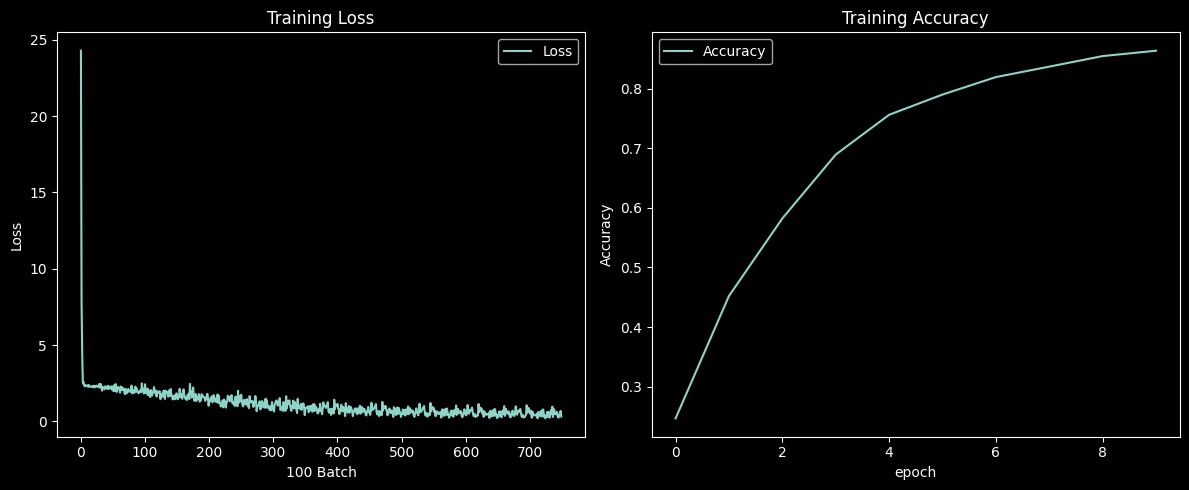

Test accuracy: 86.33999999999999%


In [3]:
# 绘制损失和准确率曲线
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(loss_array, label='Loss')
plt.title('Training Loss')
plt.xlabel(f'{log_interval} Batch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(acc_array, label='Accuracy')
plt.title('Training Accuracy')
plt.xlabel('epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

# 测试模型
predictions = np.argmax(cnn.forward(test_x), axis=1)
accuracy = np.mean(predictions == test_y)
print(f'Test accuracy: {accuracy * 100}%')